# Hidden black holes in Gaia

**Question:** Can we find black holes that give off no light at all, just by watching the stars that orbit them wobble?

## The idea in plain words

- Most stars have a partner, and the two orbit each other. That pair is called a **binary star**.
- **Gaia** is a European space telescope that measures star positions extremely precisely. If a star has a partner, Gaia sees the star trace a tiny loop on the sky: a **wobble**.
- A **black hole** is a dead star squeezed so small that not even light escapes. A black hole that is not swallowing gas is completely dark. We can't see it, but we *can* see its gravity pulling a neighbouring star around.
- From the size of the wobble and the time one loop takes, we can work out the **mass function**: the *least* the unseen partner can weigh, measured in Suns.
- An ordinary star weighing more than about 3 Suns would shine brightly, and dead "neutron stars" can't weigh more than about 3 Suns. So **a dark partner heavier than 3 Suns is probably a black hole.**

**Data:** ESA Gaia mission, Data Release 3 (DR3, published June 2022), table `gaiadr3.nss_two_body_orbit`, from the Gaia Archive: https://gea.esac.esa.int/archive/. Anonymous access, no account needed.

## Step 0: set up

These lines load the tools: `pandas` for tables, `numpy` for maths, `matplotlib` for plots, `astroquery` to talk to the Gaia Archive. They also find the project's `data/` and `plots/` folders.

In [1]:
from pathlib import Path
import numpy as np, pandas as pd, matplotlib.pyplot as plt
from astroquery.gaia import Gaia

ROOT = Path.cwd().parent if Path.cwd().name == 'notebooks' else Path.cwd()   # the repo folder
DATA, PLOTS = ROOT / 'data', ROOT / 'plots'
DATA.mkdir(exist_ok=True); PLOTS.mkdir(exist_ok=True)

BH1, BH2 = 4373465352415301632, 5870569352746779008   # Gaia ID numbers of the two confirmed black holes
RED, BLUE, GRAY, INK = '#e34948', '#2a78d6', '#a3a29c', '#2b2b29'   # plot colours (colour-blind safe)
pd.set_option('display.width', 200)

The current archive release 3.15 contains two breaking changes. Please see https://www.cosmos.esa.int/web/gaia/news#GACSrelease315 for details. In case of questions or feedback, please consult the Gaia helpdesk at https://www.cosmos.esa.int/web/gaia/gaia-helpdesk.


## Step 1: download the binary-star orbits

We ask the Gaia Archive for every binary where Gaia measured the star's wobble, keeping only stars whose distance is measured well (`parallax / parallax_error > 10`: the distance is at least 10 times bigger than its uncertainty).

That is about 169,000 stars, but since an archive update in October 2026 one query can return at most 50,000 rows. So we download **in pages of 40,000**, sorted by ID number, and stop when a page comes back short. The result is saved in `data/`, so this only runs once (about 2 minutes).

In [2]:
PAGE = 40000
QUERY = '''SELECT TOP {n} source_id, nss_solution_type, period, parallax,
                  a_thiele_innes, b_thiele_innes, f_thiele_innes, g_thiele_innes
           FROM gaiadr3.nss_two_body_orbit
           WHERE a_thiele_innes IS NOT NULL AND parallax / parallax_error > 10 AND source_id > {after}
           ORDER BY source_id'''

orbits_file = DATA / 'gaia_dr3_nss_orbits.csv'
if not orbits_file.exists():
    pages, after = [], -1
    while True:
        page = Gaia.launch_job_async(QUERY.format(n=PAGE, after=after)).get_results().to_pandas()
        pages.append(page); print(f'page {len(pages)}: {len(page)} rows')
        if len(page) < PAGE: break
        after = page['source_id'].max()
    pd.concat(pages).to_csv(orbits_file, index=False)

t = pd.read_csv(orbits_file)
print(f'{len(t):,} binary-star orbits loaded')

169,208 binary-star orbits loaded


## Step 2: from wobble to mass

Gaia describes each wobble with four numbers called the **Thiele-Innes constants** (A, B, F, G). They encode the size, tilt and orientation of the loop. A standard formula turns them into:

- `a0`: the size of the star's loop, in **milliarcseconds** (mas). One mas is about the width of a coin seen from 5,000 km away.
- Dividing by the **parallax** (how much the star shifts as Earth goes round the Sun, which tells us its distance) converts the loop size into real distance units (AU, the Earth–Sun distance).
- Kepler's law then gives the **mass function** `f_M` in Suns: (loop size in AU)³ ÷ (period in years)².

For a dark partner, `f_M` is the *minimum* mass of that partner. It is a minimum because a heavier partner orbiting a heavier visible star could produce the same wobble.

In [3]:
A, B, F, G = (t[c + '_thiele_innes'] for c in 'abfg')
u, v = (A**2 + B**2 + F**2 + G**2) / 2, A * G - B * F
t['a0_mas'] = np.sqrt(u + np.sqrt(u**2 - v**2))                       # size of the wobble [mas]
t['f_M'] = (t['a0_mas'] / t['parallax'])**3 / (t['period'] / 365.25)**2   # mass function [Suns]

cand = t[t['f_M'] > 3]
print(f'{len(cand)} of {len(t):,} binaries have f_M > 3 Suns (black-hole territory)')
t[t['source_id'].isin([BH1, BH2])][['source_id', 'nss_solution_type', 'period', 'f_M']]

19 of 169,208 binaries have f_M > 3 Suns (black-hole territory)


,source_id,nss_solution_type,period,f_M
90532,4373465352415301632,Orbital,185.765658,11.091217
143952,5870569352746779008,AstroSpectroSB1,1352.288937,6.718212


## Step 3: the big picture, and where the real black holes sit

Each grey dot is one binary. Red dots are the candidates heavier than 3 Suns. Blue stars mark **Gaia BH1** and **Gaia BH2**: two black holes that astronomers confirmed in 2022–2023 by following up these exact Gaia measurements with ground telescopes.

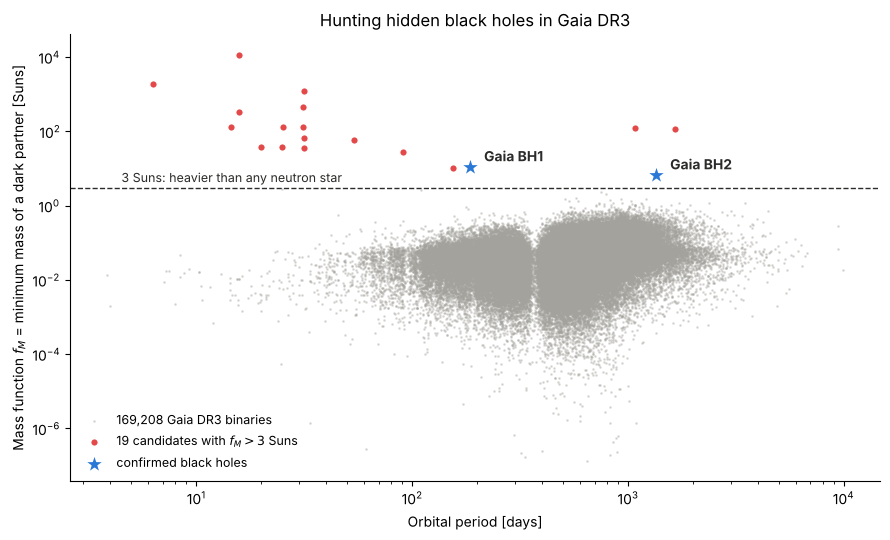

In [4]:
fig, ax = plt.subplots(figsize=(9, 5.5))
ax.scatter(t['period'], t['f_M'], s=1, c=GRAY, alpha=0.3, rasterized=True, label=f'{len(t):,} Gaia DR3 binaries')
ax.scatter(cand['period'], cand['f_M'], s=30, c=RED, edgecolors='white', linewidths=1,
           label=f'{len(cand)} candidates with $f_M > 3$ Suns')
known = t[t['source_id'].isin([BH1, BH2])]
ax.scatter(known['period'], known['f_M'], s=220, marker='*', c=BLUE, edgecolors='white', linewidths=1.2,
           label='confirmed black holes', zorder=5)
for sid, name in [(BH1, 'Gaia BH1'), (BH2, 'Gaia BH2')]:
    row = t[t['source_id'] == sid].iloc[0]
    ax.annotate(name, (row['period'], row['f_M']), xytext=(10, 4), textcoords='offset points',
                color=INK, fontsize=10, fontweight='bold')
ax.axhline(3, color=INK, lw=1, ls='--')
ax.text(4.5, 4.3, '3 Suns: heavier than any neutron star', color=INK, fontsize=9)
ax.set(xscale='log', yscale='log', xlabel='Orbital period [days]',
       ylabel='Mass function $f_M$ = minimum mass of a dark partner [Suns]',
       title='Hunting hidden black holes in Gaia DR3')
ax.legend(loc='lower left', fontsize=9, frameon=False)
for side in ['top', 'right']: ax.spines[side].set_visible(False)
fig.tight_layout(); fig.savefig(PLOTS / '22_mass_function_bh1_bh2.png', dpi=150)
plt.show()

**What this shows:** almost every binary sits in the grey cloud below 1 Sun, so its partner is an ordinary star. Only a handful of red dots rise above the dashed 3-Sun line, and the two confirmed black holes are among them. The method works. But the red dots also reach up to more than 10,000 Suns, which is not believable, so many must be measurement problems. The rest of this notebook sorts them out.

(The white gap near 365 days exists because Gaia itself orbits the Sun once a year, which makes one-year wobbles hard to measure.)

## Step 4: rank the top 20 candidates

We take the 20 binaries with the largest mass function and download a few extra facts about each one:

- `goodness_of_fit`: how well the orbit model matches Gaia's measurements. Around **0 is a good fit**; above about 3 means the model doesn't match the data well.
- `parallax`: turned into a **distance in light-years**.
- `nss_solution_type`: which kind of orbit model Gaia used (explained in Step 5).

In [5]:
top = t.nlargest(20, 'f_M')
details_file = DATA / 'gaia_dr3_top20_details.csv'
if not details_file.exists():
    ids = ','.join(str(i) for i in top['source_id'])
    q = f'''SELECT source_id, goodness_of_fit, eccentricity FROM gaiadr3.nss_two_body_orbit
            WHERE source_id IN ({ids})'''
    Gaia.launch_job_async(q).get_results().to_pandas().to_csv(details_file, index=False)

top = top.merge(pd.read_csv(details_file), on='source_id')
top['distance_ly'] = 1000 / top['parallax'] * 3.26        # parallax [mas] -> distance [parsec] -> light-years
top['known_as'] = top['source_id'].map({BH1: 'Gaia BH1', BH2: 'Gaia BH2'}).fillna('')
top.insert(0, 'rank', range(1, len(top) + 1))
top[['rank', 'source_id', 'known_as', 'nss_solution_type', 'period', 'f_M', 'goodness_of_fit', 'distance_ly']].round(2)

,rank,source_id,known_as,nss_solution_type,period,f_M,goodness_of_fit,distance_ly
0,1,5991734159714775296,,OrbitalAlternative,15.74,11486.62,2.60,5594.41
1,2,3316050687674598656,,OrbitalAlternative,6.29,1918.51,1.11,2270.77
2,3,5928370816455687808,,OrbitalAlternative,31.59,1196.21,1.52,5758.61
3,4,632497706010874240,,OrbitalAlternative,31.39,460.07,0.96,2200.76
4,5,1533365584518328576,,OrbitalAlternative,15.69,337.93,-0.38,2793.84
5,6,1538284425878995712,,OrbitalAlternative,14.47,131.59,0.35,1791.22
6,7,5959603097090964992,,OrbitalAlternative,25.23,130.88,0.57,1613.50
7,8,4491401821468887552,,OrbitalAlternative,31.31,129.63,1.68,2476.30
8,9,3640889032890567040,,Orbital,1076.22,121.47,10.33,337.52
9,10,4467000291193143808,,Orbital,1647.58,111.84,4.88,5840.81


## Step 5: why most "candidates" are not real

Real discoveries are rare; measurement glitches are common. Astronomers look for **warning signs**. We check five, using only Gaia's own numbers:

1. **Shaky fit type.** Gaia labels some orbits `OrbitalAlternative`, which its documentation defines as an "alternative orbital model mainly for low S/N systems". S/N (signal-to-noise) is how strong the signal is compared with the random noise, so low S/N means a weak, noisy measurement.
2. **Suspicious ~31.5-day period.** Gaia's spinning scan pattern repeats about every 63 days, and 31.5 days is exactly half of that. Real black holes would have all sorts of periods, so a pile-up at one period hints that the "wobble" comes from the telescope's own rhythm.
3. **Orbit longer than the data.** DR3 used about 34 months (about 1,038 days) of observations. If one orbit takes longer than that, Gaia never saw a full loop, so the period and size are uncertain.
4. **Model fits poorly.** `goodness_of_fit` above 3.
5. **Impossibly heavy.** `f_M` above 50 Suns. The heaviest black hole ever found orbiting an ordinary star is **Gaia BH3**, at about 33 Suns.

A warning sign is a reason for suspicion, **not proof**. Real objects can trip one (see BH2 below), which is why candidates get checked with other telescopes.

In [6]:
DR3_DAYS = 1038       # length of the DR3 observing window
flags = pd.DataFrame({
    'Shaky fit type':           top['nss_solution_type'].str.startswith('OrbitalAlternative'),
    '~31.5-day period':         (top['period'] - 31.5).abs() < 1,
    'Orbit longer than data':   top['period'] > DR3_DAYS,
    'Model fits poorly':        top['goodness_of_fit'] > 3,
    'Impossibly heavy (>50)':   top['f_M'] > 50,
})
top['warnings'] = flags.sum(axis=1)

all_alt = t['nss_solution_type'].str.startswith('OrbitalAlternative').mean()
print(f'"Shaky fit type" orbits: {all_alt:.1%} of ALL binaries, but {flags["Shaky fit type"].mean():.0%} of the top 20')
print(f'Top-20 candidates with at least one warning sign: {(top["warnings"] > 0).sum()} of 20')
top[['rank', 'known_as', 'period', 'f_M', 'warnings']].round(1)

"Shaky fit type" orbits: 0.4% of ALL binaries, but 75% of the top 20
Top-20 candidates with at least one warning sign: 19 of 20


,rank,known_as,period,f_M,warnings
0,1,,15.7,11486.6,2
1,2,,6.3,1918.5,2
2,3,,31.6,1196.2,3
3,4,,31.4,460.1,3
4,5,,15.7,337.9,2
5,6,,14.5,131.6,2
6,7,,25.2,130.9,2
7,8,,31.3,129.6,3
8,9,,1076.2,121.5,3
9,10,,1647.6,111.8,3


### A picture of the warning signs

Each row is one of the top 20 candidates; each column is one warning sign. A red square means that warning sign is present.

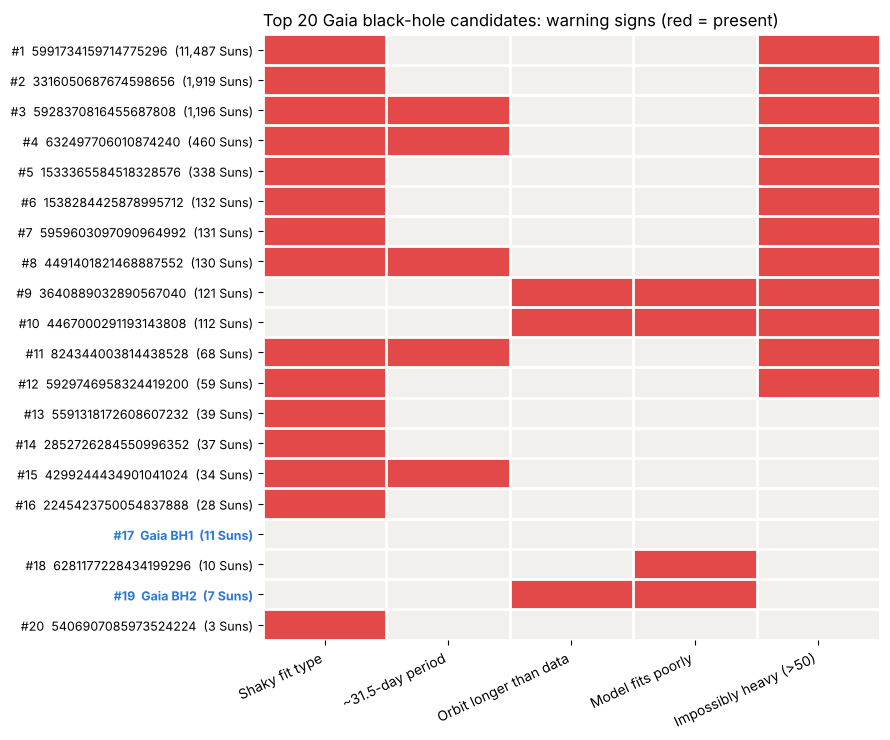

In [7]:
labels = [f"#{r.rank}  {r.known_as or r.source_id}  ({r.f_M:,.0f} Suns)" for r in top.itertuples()]
fig, ax = plt.subplots(figsize=(9, 7.5))
ax.imshow(flags.values.astype(int), cmap=plt.matplotlib.colors.ListedColormap(['#f1f0ec', RED]), aspect='auto')
ax.set_xticks(range(flags.shape[1]), flags.columns, rotation=25, ha='right')
ax.set_yticks(range(len(labels)), labels, fontsize=9)
for i, name in enumerate(top['known_as']):             # highlight the confirmed black holes
    if name: ax.get_yticklabels()[i].set(color=BLUE, fontweight='bold')
ax.set_xticks(np.arange(-.5, flags.shape[1]), minor=True); ax.set_yticks(np.arange(-.5, len(top)), minor=True)
ax.grid(which='minor', color='white', linewidth=2); ax.tick_params(which='minor', length=0)
for s in ax.spines.values(): s.set_visible(False)
ax.set_title('Top 20 Gaia black-hole candidates: warning signs (red = present)', loc='left')
fig.tight_layout(); fig.savefig(PLOTS / '22_candidate_warning_signs.png', dpi=150)
plt.show()

### Zoom in: the 31.5-day pile-up

Here are just the top 20, with the shaky fit type in red and everything else in blue. The shaded band marks the ~31.5-day period, and the dashed line marks the length of the DR3 data.

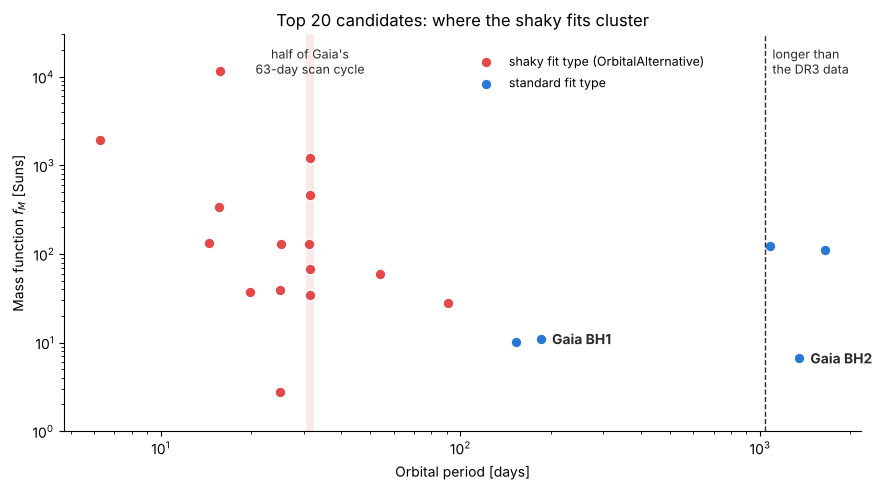

In [8]:
shaky = flags['Shaky fit type']
fig, ax = plt.subplots(figsize=(9, 5))
ax.axvspan(30.5, 32.5, color=RED, alpha=0.12, lw=0)
ax.text(31.5, 2.2e4, "half of Gaia's\n63-day scan cycle", ha='center', va='top', fontsize=9, color=INK)
ax.axvline(DR3_DAYS, color=INK, lw=1, ls='--')
ax.text(DR3_DAYS * 1.06, 2.2e4, 'longer than\nthe DR3 data', va='top', fontsize=9, color=INK)
ax.scatter(top.loc[shaky, 'period'], top.loc[shaky, 'f_M'], s=60, c=RED, edgecolors='white', label='shaky fit type (OrbitalAlternative)')
ax.scatter(top.loc[~shaky, 'period'], top.loc[~shaky, 'f_M'], s=60, c=BLUE, edgecolors='white', label='standard fit type')
for r in top[top['known_as'] != ''].itertuples():
    ax.annotate(r.known_as, (r.period, r.f_M), xytext=(8, -4), textcoords='offset points', fontsize=10, fontweight='bold', color=INK)
ax.set(xscale='log', yscale='log', xlabel='Orbital period [days]', ylabel='Mass function $f_M$ [Suns]',
       title='Top 20 candidates: where the shaky fits cluster', ylim=(1, 3e4))
ax.legend(loc='upper left', bbox_to_anchor=(0.5, 0.98), frameon=False, fontsize=9)
for side in ['top', 'right']: ax.spines[side].set_visible(False)
fig.tight_layout(); fig.savefig(PLOTS / '22_top20_periods.png', dpi=150)
plt.show()

## What we learned

- Of about 169,000 binaries, only a couple of dozen have a partner that *seems* heavier than 3 Suns.
- Most of those are **measurement problems, not black holes**: weak "shaky" fits, periods that match Gaia's own scanning rhythm, orbits longer than the data, or masses no star could leave behind.
- **Gaia BH1 is the cleanest object in the top 20, with no warning signs at all.** That is a big part of why it was the first one confirmed.
- **Gaia BH2 trips two warning signs** (its orbit is longer than the data and the fit is imperfect), yet it is real. Astronomers confirmed it by measuring the star's speed with ground-based telescopes. Warning signs tell you where to be careful, not what the answer is.

## Next steps

- **Stretch goal:** estimate each partner's minimum mass by assuming a mass for the visible star (for example 1 Sun) and solving the mass-function equation.
- **Gaia DR4** comes out on **2 December 2026**, with about twice as many years of data. Gaia BH3 (33 Suns) was found in early DR4 data, so DR4 is the natural follow-up for this project.

*Data: ESA Gaia mission, Gaia DR3 (Gaia Collaboration 2023), `gaiadr3.nss_two_body_orbit`, https://gea.esac.esa.int/archive/*